Epoch  50 | Train Loss: 0.1703 | Val Loss: 0.3348
Epoch 100 | Train Loss: 0.0712 | Val Loss: 0.3360
Epoch 150 | Train Loss: 0.0481 | Val Loss: 0.3577
Epoch 200 | Train Loss: 0.0416 | Val Loss: 0.3980
Epoch 250 | Train Loss: 0.0350 | Val Loss: 0.4124
Epoch 300 | Train Loss: 0.0325 | Val Loss: 0.4252
Epoch 350 | Train Loss: 0.0319 | Val Loss: 0.4465
Epoch 400 | Train Loss: 0.0284 | Val Loss: 0.4446
Epoch 450 | Train Loss: 0.0278 | Val Loss: 0.4404
Epoch 500 | Train Loss: 0.0265 | Val Loss: 0.4666
Neural Network Results:
MSE: 1632843177929.13 | RMSE: 1277827.52 | R2: 0.5274
Traditional ML Results:
Linear Regression | MSE: 1142623741873.05 | RMSE: 1068935.80 | R2: 0.6693
SVR               | MSE: 1916785735936.37 | RMSE: 1384480.31 | R2: 0.4452


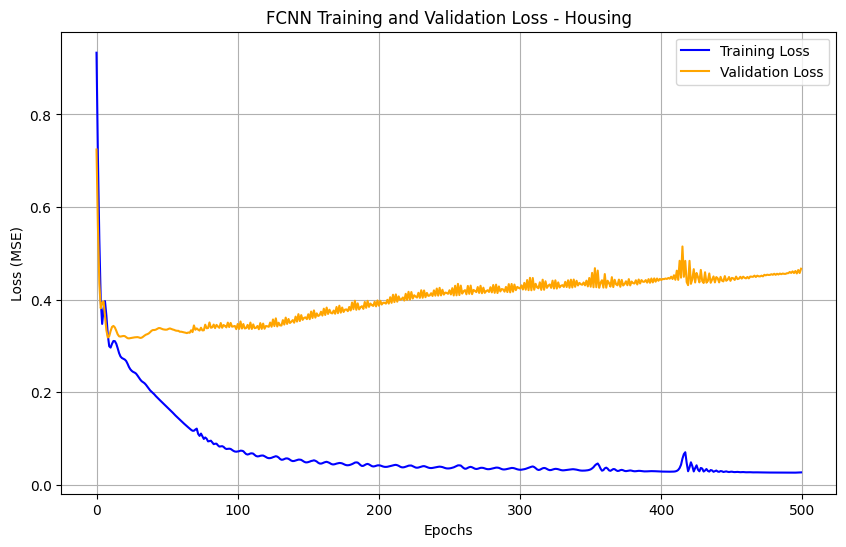

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("/content/Housing.csv")
binary_vars = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
for var in binary_vars:
    data[var] = data[var].map({"yes": 1, "no": 0})

feature_cols = ["area", "bedrooms", "bathrooms", "stories", "mainroad", "guestroom",
                "basement", "hotwaterheating", "airconditioning", "parking", "prefarea"]
X = data[feature_cols].values
y = data["price"].values
m = len(y)

np.random.seed(7)
indices = np.random.permutation(m)
split_index = int(0.8 * m)
train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train, y_train = X[train_indices], y[train_indices]
X_test, y_test = X[test_indices], y[test_indices]

# Standardize inputs
mean_X, std_X = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean_X) / std_X
X_test = (X_test - mean_X) / std_X

mean_y, std_y = y_train.mean(), y_train.std()
y_train_scaled = (y_train - mean_y) / std_y
y_test_scaled = (y_test - mean_y) / std_y

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32).view(-1, 1)

class HousingNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(11, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)

model = HousingNet()
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

n_epochs = 500
train_losses = []
val_losses = []

for epoch in range(1, n_epochs + 1):
    model.train()
    optimizer.zero_grad()

    t_p = model(X_train_t)
    loss = loss_fn(t_p, y_train_t)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        t_p_val = model(X_test_t)
        val_loss = loss_fn(t_p_val, y_test_t)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if epoch % 50 == 0:
        print(f'Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f}')

model.eval()
with torch.no_grad():
    preds_scaled = model(X_test_t).numpy().flatten()
    preds = (preds_scaled * std_y) + mean_y

mse_nn = mean_squared_error(y_test, preds)
rmse_nn = np.sqrt(mse_nn)
r2_nn = r2_score(y_test, preds)

print("Neural Network Results:")
print(f"MSE: {mse_nn:.2f} | RMSE: {rmse_nn:.2f} | R2: {r2_nn:.4f}")

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
preds_lin = lin_reg.predict(X_test)
mse_lin = mean_squared_error(y_test, preds_lin)
rmse_lin = np.sqrt(mse_lin)
r2_lin = r2_score(y_test, preds_lin)

svr = SVR(kernel='rbf', C=100, epsilon=0.1)
svr.fit(X_train, y_train_scaled)
preds_svr_scaled = svr.predict(X_test)
preds_svr = (preds_svr_scaled * std_y) + mean_y
mse_svr = mean_squared_error(y_test, preds_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, preds_svr)

print("Traditional ML Results:")
print(f"Linear Regression | MSE: {mse_lin:.2f} | RMSE: {rmse_lin:.2f} | R2: {r2_lin:.4f}")
print(f"SVR               | MSE: {mse_svr:.2f} | RMSE: {rmse_svr:.2f} | R2: {r2_svr:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(train_losses, label="Training Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.title("FCNN Training and Validation Loss - Housing")
plt.legend()
plt.grid(True)
plt.show()

Epoch  20 | Train Loss: 0.5243 | Val Loss: 0.5178 | Val Acc: 0.9211
Epoch  40 | Train Loss: 0.2779 | Val Loss: 0.2757 | Val Acc: 0.9474
Epoch  60 | Train Loss: 0.1379 | Val Loss: 0.1437 | Val Acc: 0.9649
Epoch  80 | Train Loss: 0.0901 | Val Loss: 0.0970 | Val Acc: 0.9649
Epoch 100 | Train Loss: 0.0703 | Val Loss: 0.0804 | Val Acc: 0.9825
Neural Network Results:
Accuracy: 0.9825 | Precision: 0.9737 | Recall: 1.0000 | F1: 0.9867
Traditional ML Results:
Logistic Reg | Acc: 0.9825 | Prec: 0.9737 | Rec: 1.0000 | F1: 0.9867
SVM          | Acc: 0.9825 | Prec: 0.9737 | Rec: 1.0000 | F1: 0.9867


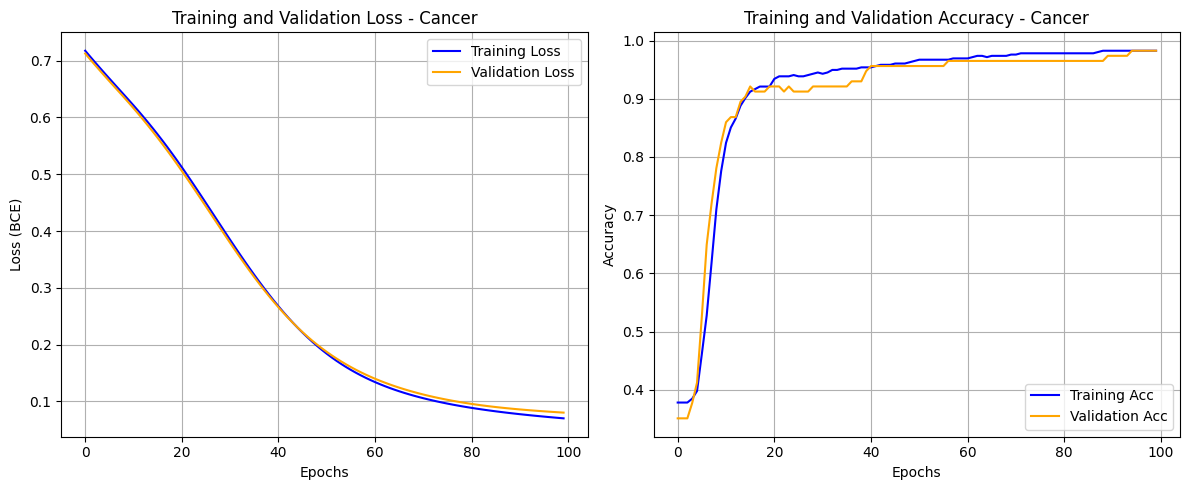

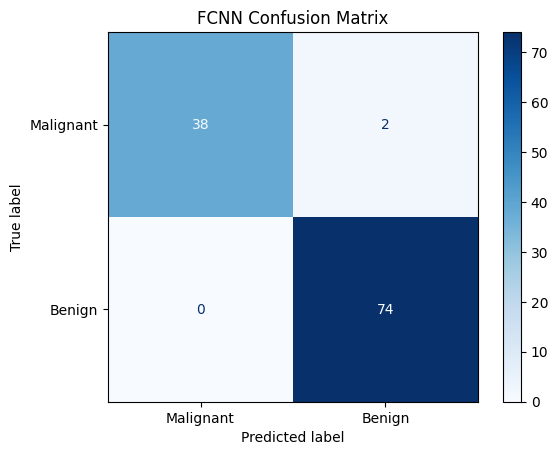

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target # 0 = malignant, 1 = benign

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

class CancerNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(30, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.sigmoid(self.fc3(x))

model = CancerNet()
loss_fn = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 100
train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(1, n_epochs + 1):
    model.train()
    optimizer.zero_grad()

    t_p = model(X_train_t)
    loss = loss_fn(t_p, y_train_t)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        t_p_val = model(X_test_t)
        val_loss = loss_fn(t_p_val, y_test_t)

        train_preds = (t_p > 0.5).float()
        val_preds = (t_p_val > 0.5).float()
        train_acc = (train_preds == y_train_t).float().mean().item()
        val_acc = (val_preds == y_test_t).float().mean().item()

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    if epoch % 20 == 0:
        print(f'Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f} | Val Acc: {val_acc:.4f}')

model.eval()
with torch.no_grad():
    final_preds = (model(X_test_t) > 0.5).float().numpy().flatten()

acc_nn = accuracy_score(y_test, final_preds)
prec_nn = precision_score(y_test, final_preds)
rec_nn = recall_score(y_test, final_preds)
f1_nn = f1_score(y_test, final_preds)

print("Neural Network Results:")
print(f"Accuracy: {acc_nn:.4f} | Precision: {prec_nn:.4f} | Recall: {rec_nn:.4f} | F1: {f1_nn:.4f}")

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)
preds_lr = log_reg.predict(X_test)

svm = SVC(kernel='rbf')
svm.fit(X_train, y_train)
preds_svm = svm.predict(X_test)

print("Traditional ML Results:")
print(f"Logistic Reg | Acc: {accuracy_score(y_test, preds_lr):.4f} | Prec: {precision_score(y_test, preds_lr):.4f} | Rec: {recall_score(y_test, preds_lr):.4f} | F1: {f1_score(y_test, preds_lr):.4f}")
print(f"SVM          | Acc: {accuracy_score(y_test, preds_svm):.4f} | Prec: {precision_score(y_test, preds_svm):.4f} | Rec: {recall_score(y_test, preds_svm):.4f} | F1: {f1_score(y_test, preds_svm):.4f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Loss (BCE)")
plt.title("Training and Validation Loss - Cancer")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Training Acc", color="blue")
plt.plot(val_accs, label="Validation Acc", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Cancer")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, final_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Malignant", "Benign"])
disp.plot(cmap=plt.cm.Blues)
plt.title("FCNN Confusion Matrix")
plt.show()